# Plant Disease Detection Using Deep Learning

## Objective

The objective of this project is to classify plant leaf images into healthy or diseased categories using a Convolutional Neural Network (CNN).

## Workflow

1. Load the plant disease dataset.
2. Explore and visualize the images.
3. Preprocess the images.
4. Build and train a CNN model.
5. Evaluate the model.
6. Predict the disease class of a new leaf image.
7. Save the trained model for future use.

In [3]:
import os
import numpy as np 
import matplotlib.pyplot as plt 
import tensorflow as tf
from sklearn.model_selection import train_test_split

In [4]:
dataset_path="New Plant Diseases Dataset(Augmented)"
print(os.listdir(dataset_path))

['New Plant Diseases Dataset(Augmented)']


In [5]:



dataset_path = os.path.join(
    os.getcwd(),
    "New Plant Diseases Dataset(Augmented)",
    "New Plant Diseases Dataset(Augmented)",
    "train"
)

image_paths = []
labels = []

print("Dataset path:", dataset_path)
print("Path exists:", os.path.exists(dataset_path))

# Load images from each disease class folder
for class_name in os.listdir(dataset_path):
    class_path = os.path.join(dataset_path, class_name)

    if os.path.isdir(class_path):
        for image_name in os.listdir(class_path):
            if image_name.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp")
            ):
                image_path = os.path.join(class_path, image_name)

                image_paths.append(image_path)
                labels.append(class_name)

print("Total images:", len(image_paths))
print("Total classes:", len(set(labels)))
print("Sample image:", image_paths[0] if image_paths else "No images found")
print("Sample label:", labels[0] if labels else "No labels found")


Dataset path: c:\Users\Dell\OneDrive\Desktop\plant desease detection\New Plant Diseases Dataset(Augmented)\New Plant Diseases Dataset(Augmented)\train
Path exists: True
Total images: 9587
Total classes: 5
Sample image: c:\Users\Dell\OneDrive\Desktop\plant desease detection\New Plant Diseases Dataset(Augmented)\New Plant Diseases Dataset(Augmented)\train\Apple___Apple_scab\00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335.JPG
Sample label: Apple___Apple_scab


In [6]:
X_train,X_temp,y_train,y_temp=train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

X_valid,X_test,y_valid,y_test=train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp

)

print("Traning images:",len(X_train))
print("Validation images:",len(X_valid))
print("Testing images:",len(X_test))

Traning images: 6710
Validation images: 1438
Testing images: 1439


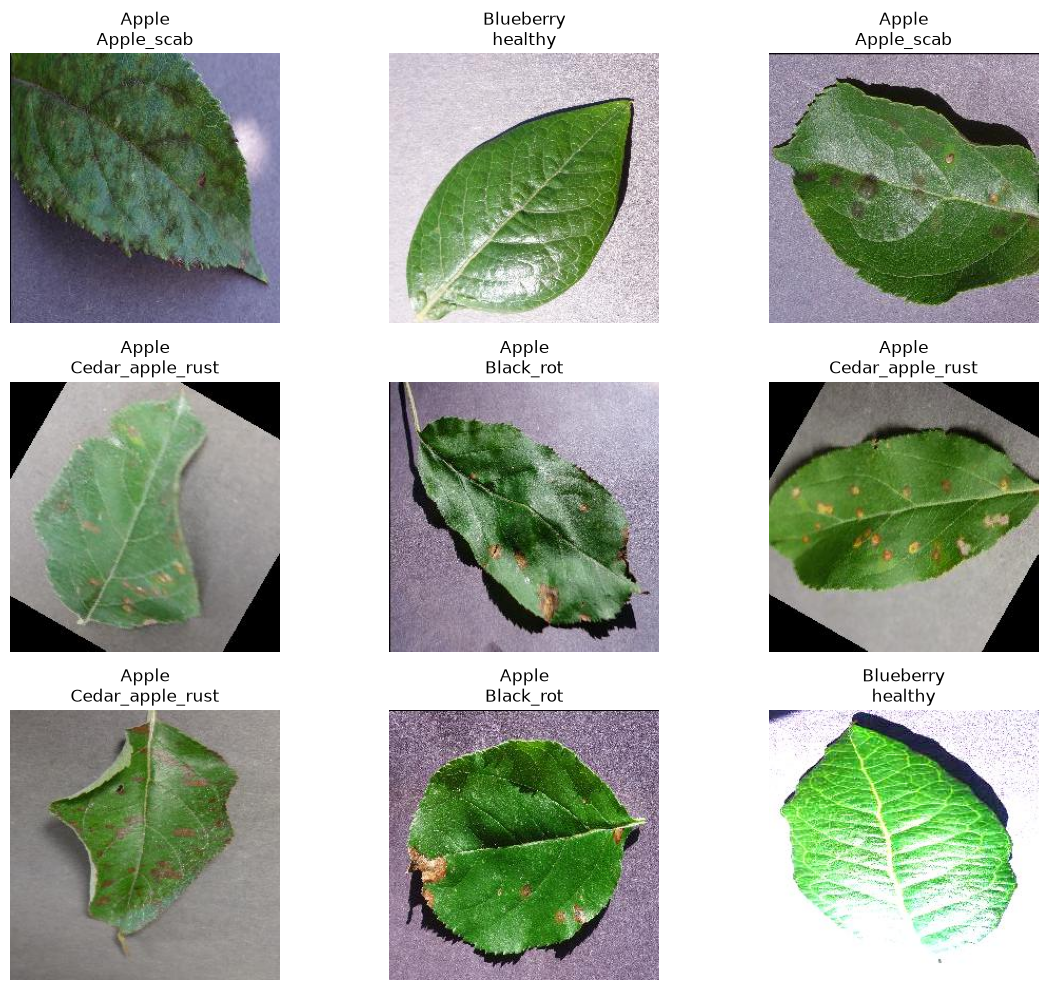

In [7]:

import matplotlib.pyplot as plt
from PIL import Image
import random

# Display 9 random leaf images
plt.figure(figsize=(12, 10))

indices = random.sample(range(len(X_train)), 9)

for i, idx in enumerate(indices):
    image = Image.open(X_train[idx]).convert("RGB")

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(y_train[idx].replace("___", "\n"))
    plt.axis("off")

plt.tight_layout()
plt.show()


In [8]:

import numpy as np
from PIL import Image

IMG_SIZE = 128

def preprocess_images(image_paths):
    images = []

    for path in image_paths:
        # Load image and convert to RGB
        img = Image.open(path).convert("RGB")

        # Resize image
        img = img.resize((IMG_SIZE, IMG_SIZE))

        # Convert to NumPy array and normalize
        img = np.array(img, dtype=np.float32) / 255.0

        images.append(img)

    return np.array(images)

# Preprocess training, validation and testing images
X_train_img = preprocess_images(X_train)
X_valid_img = preprocess_images(X_valid)
X_test_img = preprocess_images(X_test)

print("Training shape:", X_train_img.shape)
print("Validation shape:", X_valid_img.shape)
print("Testing shape:", X_test_img.shape)

print("Minimum pixel value:", X_train_img.min())
print("Maximum pixel value:", X_train_img.max())


Training shape: (6710, 128, 128, 3)
Validation shape: (1438, 128, 128, 3)
Testing shape: (1439, 128, 128, 3)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [9]:

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

# Fit on all class names
label_encoder.fit(labels)

y_train_encoded = label_encoder.transform(y_train)
y_valid_encoded = label_encoder.transform(y_valid)
y_test_encoded = label_encoder.transform(y_test)

num_classes = len(label_encoder.classes_)

print("Number of classes:", num_classes)
print("Disease classes:")
print(label_encoder.classes_)


Number of classes: 5
Disease classes:
['Apple___Apple_scab' 'Apple___Black_rot' 'Apple___Cedar_apple_rust'
 'Apple___healthy' 'Blueberry___healthy']


In [10]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout,
    Input
)

model = Sequential([
    Input(shape=(128, 128, 3)),

    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation="relu"),
    Dropout(0.5),

    Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,285 (12.61 MB)

 Trainable params: 3,305,285 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train_img,
    y_train_encoded,
    validation_data=(X_valid_img, y_valid_encoded),
    epochs=15,
    batch_size=32,
    callbacks=[early_stop]
)


Epoch 1/15
210/210 ━━━━━━━━━━━━━━━━━━━━ 178s 752ms/step - accuracy: 0.6943 - loss: 0.8005 - val_accuracy: 0.8901 - val_loss: 0.3173
Epoch 2/15
210/210 ━━━━━━━━━━━━━━━━━━━━ 148s 702ms/step - accuracy: 0.8666 - loss: 0.3822 - val_accuracy: 0.9019 - val_loss: 0.3027
Epoch 3/15
210/210 ━━━━━━━━━━━━━━━━━━━━ 192s 657ms/step - accuracy: 0.9043 - loss: 0.2673 - val_accuracy: 0.9298 - val_loss: 0.2019
Epoch 4/15
210/210 ━━━━━━━━━━━━━━━━━━━━ 134s 636ms/step - accuracy: 0.9277 - loss: 0.1966 - val_accuracy: 0.9360 - val_loss: 0.1765
Epoch 5/15
210/210 ━━━━━━━━━━━━━━━━━━━━ 159s 755ms/step - accuracy: 0.9468 - loss: 0.1415 - val_accuracy: 0.9576 - val_loss: 0.1280
Epoch 6/15
210/210 ━━━━━━━━━━━━━━━━━━━━ 174s 604ms/step - accuracy: 0.9547 - loss: 0.1288 - val_accuracy: 0.9562 - val_loss: 0.1215
Epoch 7/15
210/210 ━━━━━━━━━━━━━━━━━━━━ 133s 575ms/step - accuracy: 0.9607 - loss: 0.1205 - val_accuracy: 0.9534 - val_loss: 0.1336
Epoch 8/15
210/210 ━━━━━━━━━━━━━━━━━━━━ 116s 552ms/step - accuracy: 0.9648 -

In [12]:

test_loss, test_accuracy = model.evaluate(
    X_test_img,
    y_test_encoded,
    batch_size=32,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


45/45 ━━━━━━━━━━━━━━━━━━━━ 9s 190ms/step - accuracy: 0.9778 - loss: 0.0616
Test Loss: 0.0616
Test Accuracy: 97.78%


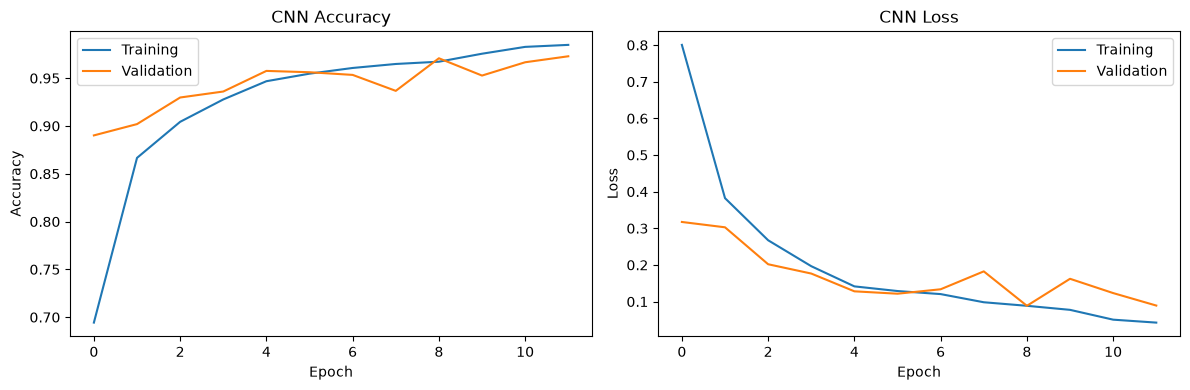

In [13]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [14]:
import os
import json

os.makedirs("saved_model", exist_ok=True)

model.save("saved_model/plant_disease_cnn.keras")

with open("saved_model/class_names.json", "w", encoding="utf-8") as f:
    json.dump(
        label_encoder.classes_.tolist(),
        f,
        indent=4
    )